In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
import json
import torch
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from tqdm import tqdm
from typing import Dict
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import precision_recall_fscore_support

project_root = Path.cwd().parent
src_root = project_root / "src"
for p in [str(project_root), str(src_root)]:
    if p not in sys.path:
        sys.path.insert(0, p)

from model.model import MultitaskMLP, MultitaskMLPWithQRegression
from data.datasets import RawFeatureDataset, dataset_from_schema
from data.split import split_dataset
from predicates.definitions import MACCS_DEFINITIONS


In [4]:
import matplotlib.font_manager as fm
import requests

# Download a valid Roboto TTF from Google Fonts repository
roboto_urls = [
    "https://raw.githubusercontent.com/google/fonts/main/ofl/roboto/Roboto%5Bwdth%2Cwght%5D.ttf",
    "https://raw.githubusercontent.com/google/fonts/main/apache/roboto/static/Roboto-Regular.ttf",
]

response = None
for roboto_url in roboto_urls:
    r = requests.get(roboto_url, timeout=30)
    if r.ok:
        response = r
        break

if response is None:
    raise RuntimeError("Could not download a Roboto font file from known URLs.")

font_path = "Roboto-Regular.ttf"
with open(font_path, "wb") as f:
    f.write(response.content)

# Register font with matplotlib
fm.fontManager.addfont(font_path)
plt.rcParams["font.family"] = "Roboto"

In [5]:
# Set font to roboto
plt.rcParams["font.family"] = "Roboto"

In [6]:
DATA_PATH = Path("../data/multitask_mlp_hardcoded.test.json")
SCHEMA_PATH = Path("../data/feature_vector_mixed_schema.json")
OUTPUT_PATH = Path("../models/final/multitask_mlp_mixed_best.pt")


In [7]:
# Load the dataset
dataset = RawFeatureDataset(data_path=DATA_PATH, schema_path=SCHEMA_PATH)
print(f"Dataset loaded with {len(dataset)} samples.")

Dataset loaded with 100761 samples.


In [9]:
# Pickle the dataset
pickle_path = Path("../data/mixed_test.pkl")

In [10]:
with open(pickle_path, "wb") as f:
    pickle.dump(dataset, f)
print(f"Dataset pickled to {pickle_path}.")

Dataset pickled to ../data/mixed_test.pkl.


In [11]:
# Load from pickle
with open(pickle_path, "rb") as f:
    dataset = pickle.load(f)
print(f"Dataset loaded from pickle with {len(dataset)} samples.")

Dataset loaded from pickle with 100761 samples.


In [9]:
# Split the test set into calibration and test sets
calibration_ds, test_ds, _ = split_dataset(dataset, train_fraction=0.4, val_fraction=0.6, calibration_fraction=0, test_fraction=0, seed=42)

# Cast to RawFeatureDataset to access normalisation
calibration_ds = RawFeatureDataset.from_subset(calibration_ds)
test_ds = RawFeatureDataset.from_subset(test_ds)
print(f"Calibration set: {len(calibration_ds)} samples")
print(f"Test set: {len(test_ds)} samples")

Grouping records by SMILES: 5508it [00:01, 2819.10it/s]


KeyboardInterrupt: 

In [9]:
# Normalise the continuous features
# I need to change this to use the normalisation stats from the training set, but I do not have those saved.

# Load the mean and stds from json
with open("../data/multitask_mlp_hardcoded.normalisation.json", "r") as f:
    normalisation_stats = json.load(f)

mean, std = normalisation_stats["mean"], normalisation_stats["std"]
print(f"Loaded normalisation stats: mean={mean}, std={std}")
_, _ = test_ds.normalise_continuous(mean, std)
_, _ = calibration_ds.normalise_continuous(mean, std)

Loaded normalisation stats: mean=[2.017406940460205, 0.4262961745262146, 6.265167236328125, 3.7547175884246826, 7.707900524139404, 52.85661697387695, 5.798068046569824, 0.4670989513397217, 7.864522933959961, 7.349009990692139, 58.08369445800781, 103.61986541748047, 0.6849406361579895, 7.724971294403076, 0.27713823318481445, 1.4737597703933716, 2.2921102046966553, 945.0389404296875, 66.83103942871094, 8.747397422790527, 8.33531379699707, 0.4120834469795227, 945.7388916015625, 0.10511194169521332, 0.10461854189634323, 7.620112419128418, 0.27712759375572205, 0.2767767012119293, 0.5129441618919373, 0.4654741585254669, 0.43600451946258545, 48.806068420410156, 4.354050159454346, 2.4838998317718506, 170.4508514404297, 3.679232597351074], std=[2.751927614212036, 0.9254239797592163, 4.171493053436279, 4.05784273147583, 2.9437973499298096, 17.989131927490234, 4.10188627243042, 0.8214291334152222, 4.329891204833984, 4.491404056549072, 17.703628540039062, 32.8455924987793, 0.9887046217918396, 4.14

In [10]:
# Load the schema
with open(SCHEMA_PATH, "r") as f:
    schema = json.load(f)

In [11]:
# Build categorical_sizes dict in the dataset's feature order to ensure matching heads
feature_schema = schema["feature_schema"]
categorical_sizes: Dict[str, int] = {}
for feat in dataset.onehot_feature_order:
    spec = feature_schema.get(feat)
    if spec['type'] != 'onehot':
        continue
    if spec is None:
        raise ValueError(f"Feature {feat} missing from schema.feature_schema")
    categorical_sizes[feat] = len(spec["onehot_names"])

In [12]:
model = MultitaskMLPWithQRegression(
    spectrum_len=1000,
    hidden_dims=[512, 256, 128],
    num_binary=int(schema.get('maccs_length', 167)),
    categorical_sizes=categorical_sizes,
    num_regression=dataset.n_continuous,
    num_quantiles=3,
    dropout=0.3,
)

In [13]:
# Load from checkpoint
checkpoint = torch.load("../models/final/multitask_mlp_mixed_best.pt", map_location=torch.device('cuda'))
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

MultitaskMLPWithQRegression(
  (backbone): Sequential(
    (0): Sequential(
      (0): Linear(in_features=1000, out_features=512, bias=True)
      (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.3, inplace=False)
    )
    (1): Sequential(
      (0): Linear(in_features=512, out_features=256, bias=True)
      (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.3, inplace=False)
    )
    (2): Sequential(
      (0): Linear(in_features=256, out_features=128, bias=True)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.3, inplace=False)
    )
  )
  (binary_head): Linear(in_features=128, out_features=167, bias=True)
  (categorical_heads): ModuleList(
    (0-52): 53 x Linear(in_features=128, out_features=2, bias=True)
  )
  (quantile_heads): ModuleList(
    (

# Testing (before conformal)

In [13]:
# Create dataloader for calibration
from torch.utils.data import DataLoader
from tqdm.asyncio import tqdm
calibration_loader = DataLoader(calibration_ds, batch_size=256, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=4, pin_memory=True)
# Run a single batch through the model to verify it works
device = torch.device('cuda') if torch.cuda.is_available() else 'cpu'
model.to(device)

# --------------------------
# Storage
# --------------------------
all_binary_logits, all_binary_targets = [], []
all_quantile_outputs, all_quantile_targets = [], []

# We initialize categorical storage lazily (we don’t know C yet)
all_categorical_logits = None
all_categorical_targets = None

with torch.no_grad():
    for spectra, targets in tqdm(test_loader, desc="Running inference on test set"):
        spectra = spectra.to(device)

        cont = targets.get("continuous", None)
        targets = {
            "binary": targets["binary"].to(device),
            "categorical": [t.to(device) for t in targets["categorical"]],
            "regression": cont.to(device) if cont is not None else None,
        }

        outputs = model(spectra)

        # -------- Binary --------
        all_binary_logits.append(outputs["binary"].cpu())
        all_binary_targets.append(targets["binary"].cpu())

        # -------- Categorical (list-based) --------
        if all_categorical_logits is None:
            num_cat_features = len(outputs["categorical"])
            all_categorical_logits = [[] for _ in range(num_cat_features)]
            all_categorical_targets = [[] for _ in range(num_cat_features)]

        for i, (logits_i, target_i) in enumerate(
            zip(outputs["categorical"], targets["categorical"])
        ):
            all_categorical_logits[i].append(logits_i.cpu())   # (B, K_i)
            all_categorical_targets[i].append(target_i.cpu())  # (B,)

        # -------- Regression --------
        if "quantile" in outputs and targets["regression"] is not None:
            q_out = torch.stack(outputs["quantile"], dim=1)  # (B, F, Q)
            all_quantile_outputs.append(q_out.cpu())
            all_quantile_targets.append(targets["regression"].cpu())

# --------------------------
# Concatenate
# --------------------------
all_binary_logits = torch.cat(all_binary_logits)
all_binary_targets = torch.cat(all_binary_targets)

all_categorical_logits = [
    torch.cat(l) for l in all_categorical_logits
]
all_categorical_targets = [
    torch.cat(t) for t in all_categorical_targets
]

all_quantile_outputs = (
    torch.cat(all_quantile_outputs) if all_quantile_outputs else None
)
all_quantile_targets = (
    torch.cat(all_quantile_targets) if all_quantile_targets else None
)

Running inference on test set: 100%|██████████| 237/237 [00:46<00:00,  5.15it/s]


In [14]:
outputs = {
    "binary": all_binary_logits.to(device),
    "categorical": all_categorical_logits,
    "quantile": all_quantile_outputs.to(device),
}
targets = {
    "binary": all_binary_targets.to(device),
    "categorical": all_categorical_targets,
    "regression": all_quantile_targets.to(device),
}

In [15]:
outputs['quantile_norm'] = outputs['quantile']
targets['regression_norm'] = targets['regression']

mean = torch.tensor(mean).to(device)
std = torch.tensor(std).to(device)

# Undo the normalisation for regression
outputs['quantile'] = outputs['quantile'] * std[:, None] + mean[:, None]
targets['regression'] = targets['regression'] * std + mean

In [15]:
# Pickle
results_path = Path("../data/multitask_mlp_mixed_test_results.pkl")

In [ ]:
with open(results_path, "wb") as f:
    pickle.dump((outputs, targets), f)
print(f"Test results pickled to {results_path}.")

Test results pickled to ../data/multitask_mlp_mixed_test_results.pkl.


In [16]:
# load from pickle
with open(results_path, "rb") as f:
    outputs, targets = pickle.load(f)
print("Test results loaded from pickle.")

Test results loaded from pickle.


In [17]:
# Print the number of targets for each task
print(f"Binary targets: {targets['binary'].shape}")
print(f"Categorical targets: {len(targets['categorical'])}")
if targets['regression'] is not None:
    print(f"Regression targets: {targets['regression'].shape}")

Binary targets: torch.Size([60456, 167])
Categorical targets: 53
Regression targets: torch.Size([60456, 36])


In [18]:
# Binary accuracy
binary_preds = (outputs["binary"] > 0).float()
binary_accs = (binary_preds == targets["binary"]).float() # (N, num_binary)
# Average to get per-feature accuracy of shape (num_binary,)
binary_accs = binary_accs.mean(dim=0)  # (num_binary,)
for i in range(binary_accs.shape[0]):
    acc_i = binary_accs[i].item()
    print(f"Binary feature {i} accuracy: {acc_i:.4f}")

Binary feature 0 accuracy: 1.0000
Binary feature 1 accuracy: 1.0000
Binary feature 2 accuracy: 1.0000
Binary feature 3 accuracy: 1.0000
Binary feature 4 accuracy: 1.0000
Binary feature 5 accuracy: 1.0000
Binary feature 6 accuracy: 1.0000
Binary feature 7 accuracy: 1.0000
Binary feature 8 accuracy: 0.9997
Binary feature 9 accuracy: 1.0000
Binary feature 10 accuracy: 1.0000
Binary feature 11 accuracy: 0.9995
Binary feature 12 accuracy: 1.0000
Binary feature 13 accuracy: 0.9995
Binary feature 14 accuracy: 0.9998
Binary feature 15 accuracy: 0.9999
Binary feature 16 accuracy: 0.9983
Binary feature 17 accuracy: 0.9993
Binary feature 18 accuracy: 0.9999
Binary feature 19 accuracy: 0.9959
Binary feature 20 accuracy: 0.9985
Binary feature 21 accuracy: 0.9998
Binary feature 22 accuracy: 0.9977
Binary feature 23 accuracy: 0.9991
Binary feature 24 accuracy: 0.9978
Binary feature 25 accuracy: 0.9982
Binary feature 26 accuracy: 0.9946
Binary feature 27 accuracy: 0.9998
Binary feature 28 accuracy: 0.

In [19]:
MACCS_DEFINITIONS[99]

{'predicate': 'has_c_c_double_bond',
 'definition': '\n            has_c_c_double_bond :-\n                double_bond_between(I, J),\n                symbol(I, "C"),\n                symbol(J, "C").\n        ',
 'domain': {0, 1}}

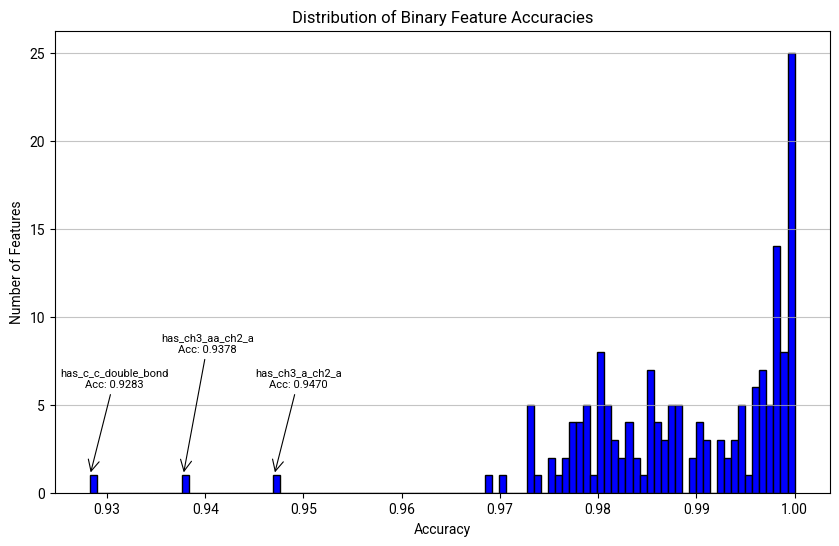

In [20]:
# Plot the distribution of binary feature accuracies
plt.figure(figsize=(10, 6))
plt.hist(binary_accs.cpu().numpy(), bins=100, color='blue', edgecolor='black')
# Annotate three worst features
worst_indices = torch.argsort(binary_accs)[:3]
for i, idx in enumerate(worst_indices):
    acc_i = binary_accs[idx].item()
    plt.annotate(f"{MACCS_DEFINITIONS[idx.item()]['predicate']}\nAcc: {acc_i:.4f}", xy=(acc_i, 1), xytext=(acc_i + 0.0025, 6 if i % 2 == 0 else 8),
                 arrowprops=dict(arrowstyle='->', lw=0.8, mutation_scale=20), fontsize=8, ha='center')
plt.title("Distribution of Binary Feature Accuracies")
plt.xlabel("Accuracy")
plt.ylabel("Number of Features")
plt.grid(axis='y', alpha=0.75)
plt.show()

In [21]:
targets["binary"].shape, binary_preds.shape

(torch.Size([60456, 167]), torch.Size([60456, 167]))

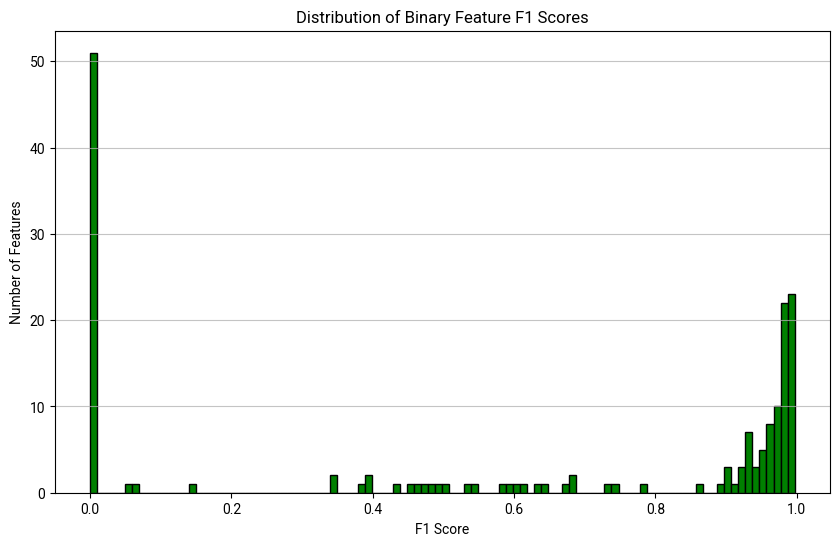

In [22]:
# Calculate accuracy, precision, recall, F1 for each binary feature

binary_evals = []
for i in range(targets["binary"].shape[1]):
    y_true = targets["binary"][:, i].cpu().numpy()
    y_pred = binary_preds[:, i].cpu().numpy()
    acc = (y_true == y_pred).mean()
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    binary_evals.append({
        "feature_index": i,
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    })

# Plot the F1 scores as a histogram
plt.figure(figsize=(10, 6))
f1_scores = [e["f1"] for e in binary_evals]
plt.hist(f1_scores, bins=100, color='green', edgecolor='black')
plt.title("Distribution of Binary Feature F1 Scores")
plt.xlabel("F1 Score")
plt.ylabel("Number of Features")
plt.grid(axis='y', alpha=0.75)
plt.show()

In [23]:
# Save the binary evals as a csv file
binary_evals_df = pd.DataFrame(binary_evals)
binary_evals_df.to_csv("../data/multitask_mlp_mixed_binary_evals.csv", index=False)
print("Binary evals saved to ../data/multitask_mlp_mixed_binary_evals.csv")

Binary evals saved to ../data/multitask_mlp_mixed_binary_evals.csv


In [24]:
def class_balance(y):
    classes, counts = np.unique(y.cpu().numpy(), return_counts=True)
    count_ratio = counts / len(y)
    return classes, counts, count_ratio

class_balances = {}
for x in binary_evals:
    maccs_key = x['feature_index'] + 1
    feature_name = MACCS_DEFINITIONS[maccs_key]['predicate'] if maccs_key in MACCS_DEFINITIONS else f"MACCS Key {maccs_key}"
    print(f"Feature: {feature_name}\n\tAccuracy: {x['accuracy']:.4f}, Precision: {x['precision']:.4f}, Recall: {x['recall']:.4f}, F1: {x['f1']:.4f}")
    classes, counts, count_ratio = class_balance(targets["binary"][:, x['feature_index']])
    class_balances[x['feature_index']] = (classes, counts, count_ratio)
    for cls, ratio in zip(classes, count_ratio):
        print(f"\tClass {int(cls)}: {ratio*100:.1f}%")

Feature: MACCS Key 1
	Accuracy: 1.0000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000
	Class 0: 100.0%
Feature: has_element_104
	Accuracy: 1.0000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000
	Class 0: 100.0%
Feature: has_group_iva_va_via_rows4to6
	Accuracy: 1.0000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000
	Class 0: 100.0%
Feature: has_actinide
	Accuracy: 1.0000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000
	Class 0: 100.0%
	Class 1: 0.0%
Feature: has_group_iiib_ivb
	Accuracy: 1.0000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000
	Class 0: 100.0%
Feature: has_lanthanide
	Accuracy: 1.0000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000
	Class 0: 100.0%
Feature: has_group_vb_vib_viib
	Accuracy: 1.0000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000
	Class 0: 100.0%
Feature: MACCS Key 8
	Accuracy: 1.0000, Precision: 0.0000, Recall: 0.0000, F1: 0.0000
	Class 0: 100.0%
	Class 1: 0.0%
Feature: has_group_viii
	Accuracy: 0.9997, Precision: 0.0000, Recall: 0.0000, F1: 0.0000
	Class 0: 100.

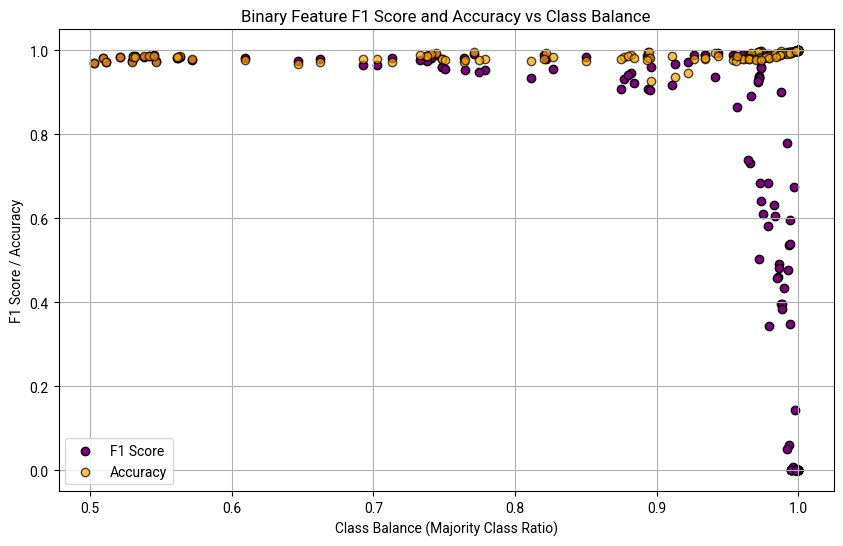

In [25]:
# Plot class balance vs F1 score for each feature
plt.figure(figsize=(10, 6))
f1_scores = [x['f1'] for x in binary_evals]
accuracies = [x['accuracy'] for x in binary_evals]
class_balance = [class_balances[x['feature_index']][2].max() for x in binary_evals]  # Get the ratio of the majority class as a measure of imbalance
plt.scatter(class_balance, f1_scores, color='purple', edgecolor='black')
plt.scatter(class_balance, accuracies, color='orange', edgecolor='black', alpha=0.7)
plt.title("Binary Feature F1 Score and Accuracy vs Class Balance")
plt.xlabel("Class Balance (Majority Class Ratio)")
plt.ylabel("F1 Score / Accuracy")
plt.grid(True)
plt.legend(["F1 Score", "Accuracy"])
plt.show()

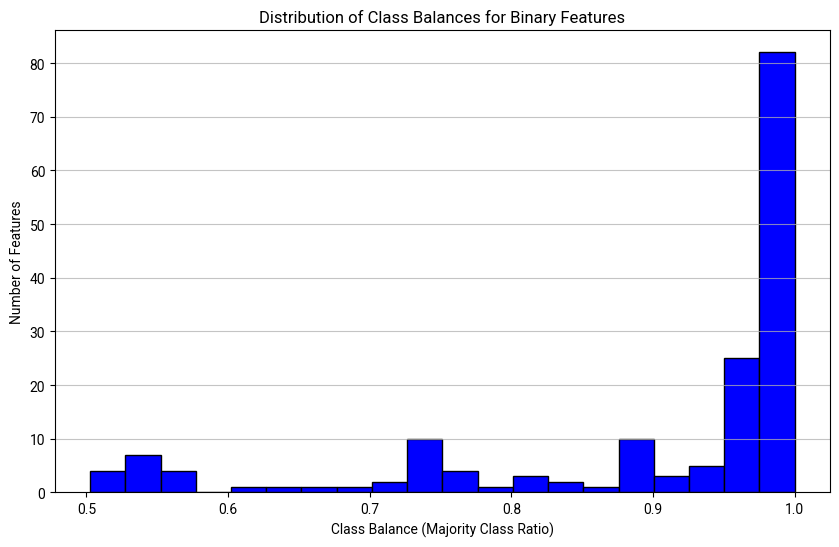

In [26]:
# Plot histogram of class balances
plt.figure(figsize=(10, 6))
balances = [class_balances[x['feature_index']][2].max() for x in binary_evals]
plt.hist(balances, bins=20, color='blue', edgecolor='black')
plt.title("Distribution of Class Balances for Binary Features")
plt.xlabel("Class Balance (Majority Class Ratio)")
plt.ylabel("Number of Features")
plt.grid(axis='y', alpha=0.75)

In [27]:
# print number of times F1 score is zero
num_f1_zero = sum(1 for x in binary_evals if x['f1'] == 0)
print(f"Number of binary features with F1 score of zero: {num_f1_zero}/{len(binary_evals)} ({num_f1_zero/len(binary_evals):.2%})")

Number of binary features with F1 score of zero: 50/167 (29.94%)


In [28]:
# proportion of features with majority class = 100%
num_majority_100 = sum(1 for b in balances if b == 1.0)
proportion_majority_100 = num_majority_100 / len(balances)
print(f"Proportion of binary features with 100% majority class: {proportion_majority_100:.2%} ({num_majority_100}/{len(balances)})")

Proportion of binary features with 100% majority class: 3.59% (6/167)


In [29]:
from sklearn.feature_selection import VarianceThreshold

majority_ratio = 0.99
threshold = majority_ratio * (1 - majority_ratio)  # Variance of a Bernoulli with p=majority_ratio
selector = VarianceThreshold(threshold=threshold)

# How many features would be removed by this threshold?
binary_data = targets["binary"].cpu().numpy()
selector.fit(binary_data)
num_features_removed = np.sum(selector.get_support() == False)
print(f"Number of binary features that would be removed by VarianceThreshold with majority ratio {majority_ratio}: {num_features_removed}/{binary_data.shape[1]} ({num_features_removed/binary_data.shape[1]:.2%})")

Number of binary features that would be removed by VarianceThreshold with majority ratio 0.99: 63/167 (37.72%)


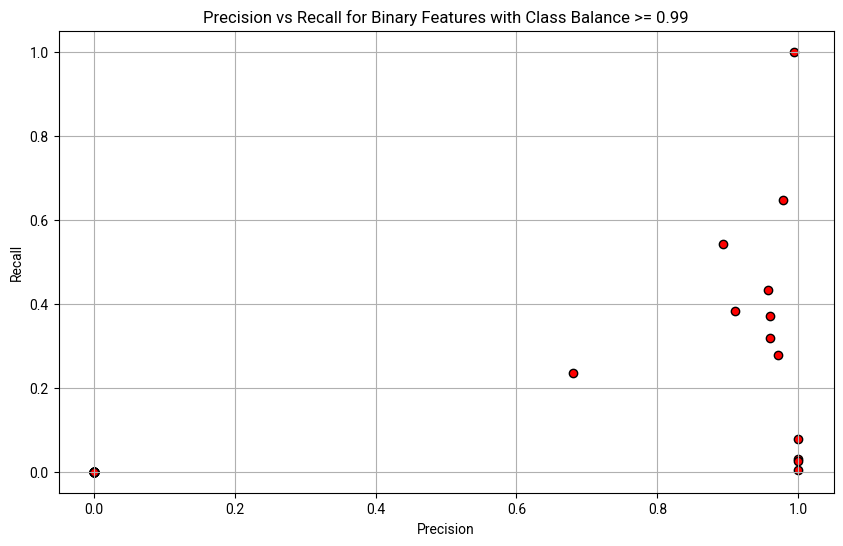

In [30]:
# Plot precision, recall, F1 for the features that would be removed by the VarianceThreshold
plt.figure(figsize=(10, 6))
for x in binary_evals:
    if class_balances[x['feature_index']][2].max() >= majority_ratio:
        plt.scatter(x['precision'], x['recall'], color='red', edgecolor='black')
plt.title(f"Precision vs Recall for Binary Features with Class Balance >= {majority_ratio}")
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.grid(True)
plt.show()

In [20]:
# Categorical Accuracy
cat_accs = []
for i, (logits_i, target_i) in enumerate(zip(outputs["categorical"], targets["categorical"])):
    cat_preds = torch.argmax(logits_i, dim=1)
    cat_acc = (cat_preds == target_i).float().mean().item()
    cat_accs.append(cat_acc)
    print(f"Categorical feature {i} accuracy: {cat_acc:.4f}")

Categorical feature 0 accuracy: 0.9987
Categorical feature 1 accuracy: 0.9884
Categorical feature 2 accuracy: 0.9895
Categorical feature 3 accuracy: 0.9965
Categorical feature 4 accuracy: 0.9877
Categorical feature 5 accuracy: 0.9841
Categorical feature 6 accuracy: 0.9897
Categorical feature 7 accuracy: 0.9934
Categorical feature 8 accuracy: 1.0000
Categorical feature 9 accuracy: 0.9870
Categorical feature 10 accuracy: 0.9877
Categorical feature 11 accuracy: 0.9991
Categorical feature 12 accuracy: 0.9868
Categorical feature 13 accuracy: 0.9961
Categorical feature 14 accuracy: 0.9852
Categorical feature 15 accuracy: 0.9984
Categorical feature 16 accuracy: 0.9999
Categorical feature 17 accuracy: 0.9992
Categorical feature 18 accuracy: 0.9950
Categorical feature 19 accuracy: 0.9978
Categorical feature 20 accuracy: 0.9998
Categorical feature 21 accuracy: 0.9934
Categorical feature 22 accuracy: 0.9985
Categorical feature 23 accuracy: 0.9990
Categorical feature 24 accuracy: 0.9808
Categorica

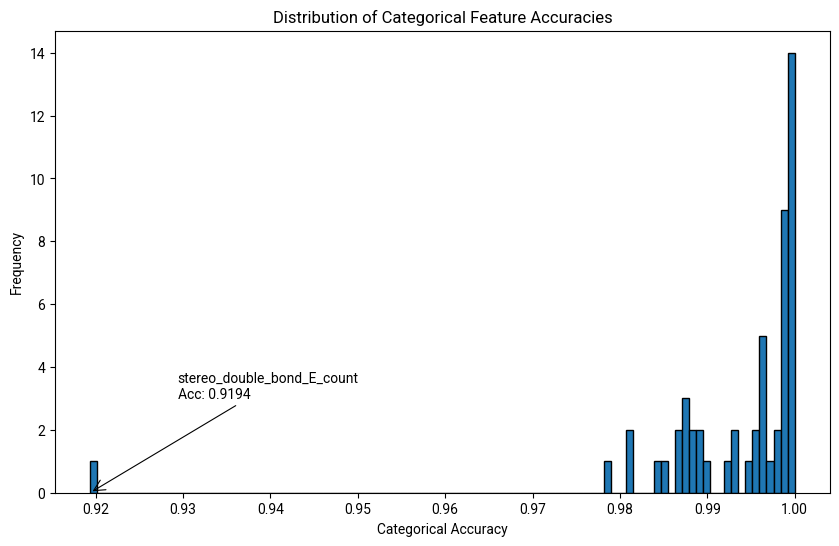

In [21]:
# Plot distribution of categorical feature accuracies
categorical_accs = []
for i, (logits_i, target_i) in enumerate(zip(outputs["categorical"], targets["categorical"])):
    cat_preds = torch.argmax(logits_i, dim=1)
    cat_acc = (cat_preds == target_i).float().mean().item()
    categorical_accs.append(cat_acc)

plt.figure(figsize=(10, 6))
plt.hist(categorical_accs, bins=100, edgecolor='black')
# Annotate worst accuracy with the name of the feature
worst_acc = min(categorical_accs)
worst_idx = categorical_accs.index(worst_acc)
worst_feature = dataset.onehot_feature_order[worst_idx]
plt.annotate(
    f"{worst_feature}\nAcc: {worst_acc:.4f}",
    xy=(worst_acc, 0),
    xytext=(worst_acc + 0.01, 3),
    arrowprops=dict(arrowstyle="->", color="black", lw=0.8, mutation_scale=20),
    fontsize=10
)
plt.xlabel("Categorical Accuracy")
plt.ylabel("Frequency")
plt.title("Distribution of Categorical Feature Accuracies")
plt.show()

In [22]:
lower = outputs['quantile'][..., 0]
lower_norm = outputs['quantile_norm'][..., 0]
median = outputs['quantile'][..., 1]
median_norm = outputs['quantile_norm'][..., 1]
upper = outputs['quantile'][..., 2]
upper_norm = outputs['quantile_norm'][..., 2]
width = upper - lower
width_norm = upper_norm - lower_norm
target = targets['regression']
target_norm = targets['regression_norm']

within = (target >= lower) & (target <= upper)
median_acc = (median == target).float().mean(dim=0)
q_coverage = within.float().mean(dim=0)
cont_feature_names = dataset.continuous_feature_order
for i, coverage in enumerate(q_coverage):
    print(f"[Quantile coverage] {cont_feature_names[i]}: {coverage:.4f}")
    print(f"[Quantile width] {cont_feature_names[i]}: {width[:, i].mean():.4f}")
    print(f"[Normalised quantile width] {cont_feature_names[i]}: {width_norm[:, i].mean():.4f}")

[Quantile coverage] alcohol: 0.7335
[Quantile width] alcohol: 0.8748
[Normalised quantile width] alcohol: 0.3179
[Quantile coverage] aliphatic_ring_count: 0.3078
[Quantile width] aliphatic_ring_count: 0.3365
[Normalised quantile width] aliphatic_ring_count: 0.3636
[Quantile coverage] branch_point_count: 0.9490
[Quantile width] branch_point_count: 1.5542
[Normalised quantile width] branch_point_count: 0.3726
[Quantile coverage] chiral_center_count: 0.7255
[Quantile width] chiral_center_count: 1.1889
[Normalised quantile width] chiral_center_count: 0.2930
[Quantile coverage] degree_1_atom_count: 0.7182
[Quantile width] degree_1_atom_count: 1.2446
[Normalised quantile width] degree_1_atom_count: 0.4228
[Quantile coverage] degree_2_atom_count: 0.9692
[Quantile width] degree_2_atom_count: 15.1353
[Normalised quantile width] degree_2_atom_count: 0.8414
[Quantile coverage] degree_3_atom_count: 0.9240
[Quantile width] degree_3_atom_count: 1.4823
[Normalised quantile width] degree_3_atom_count:

In [25]:
# Quantise predictions to integers to be physically meaningful
quantiles = outputs['quantile']
quantiles_rounded = torch.round(quantiles)

# Evaluate coverage for quantised predictions
lower_q = quantiles_rounded[..., 0]
upper_q = quantiles_rounded[..., 2]
within_q = (target >= lower_q) & (target <= upper_q)
median_acc = (quantiles_rounded[..., 1] == target).float().mean(dim=0)
width = upper_q - lower_q
norm_width = width / (target.max() - target.min())
coverage_per_feature_q = within_q.float().mean(dim=0)
for i, coverage in enumerate(coverage_per_feature_q):
    print(f"[Quantised quantile coverage] {cont_feature_names[i]}: {coverage:.4f}")
    print(f"[Quantised quantile width] {cont_feature_names[i]}: {norm_width[:, i].mean():.4f}")
    print(f"[Median accuracy] {cont_feature_names[i]}: {median_acc[i]:.4f}")

[Quantised quantile coverage] alcohol: 0.9945
[Quantised quantile width] alcohol: 0.0003
[Median accuracy] alcohol: 0.9423
[Quantised quantile coverage] aliphatic_ring_count: 0.9962
[Quantised quantile width] aliphatic_ring_count: 0.0001
[Median accuracy] aliphatic_ring_count: 0.9588
[Quantised quantile coverage] branch_point_count: 0.9033
[Quantised quantile width] branch_point_count: 0.0005
[Median accuracy] branch_point_count: 0.8098
[Quantised quantile coverage] chiral_center_count: 0.9926
[Quantised quantile width] chiral_center_count: 0.0004
[Median accuracy] chiral_center_count: 0.9287
[Quantised quantile coverage] degree_1_atom_count: 0.9897
[Quantised quantile width] degree_1_atom_count: 0.0004
[Median accuracy] degree_1_atom_count: 0.9051
[Quantised quantile coverage] degree_2_atom_count: 0.9765
[Quantised quantile width] degree_2_atom_count: 0.0058
[Median accuracy] degree_2_atom_count: 0.1708
[Quantised quantile coverage] degree_3_atom_count: 0.9913
[Quantised quantile widt

7
23
30


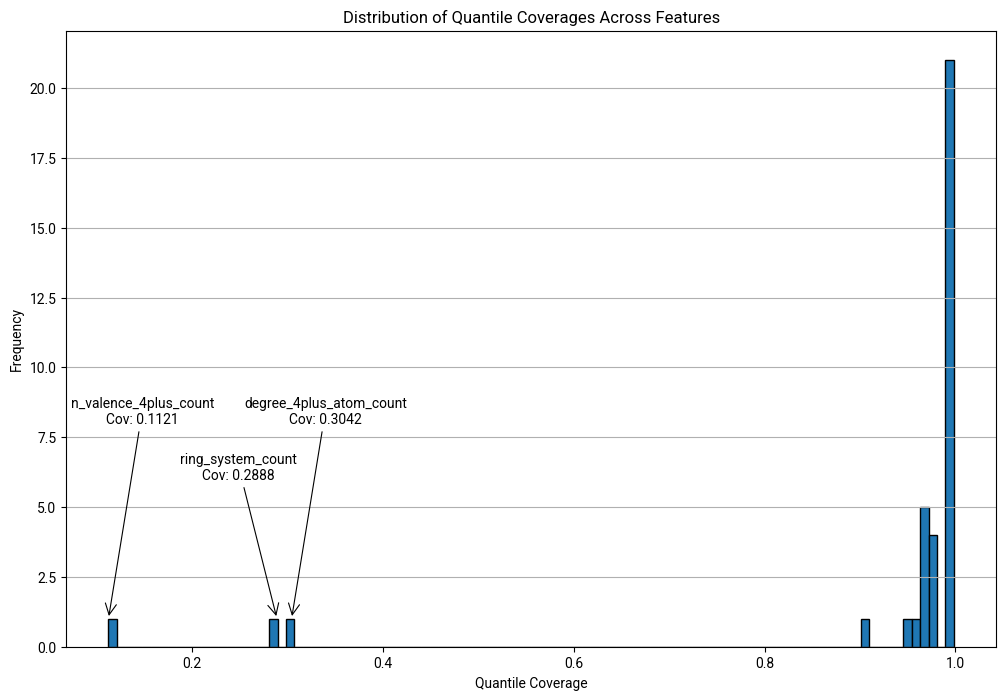

In [26]:
# Plot the distribution of quantile coverages and widths across features
plt.figure(figsize=(12, 8))
plt.hist(coverage_per_feature_q.cpu().numpy(), bins=100, edgecolor='black')
# Annotate all features with coverage < 0.5
for i, coverage in enumerate(coverage_per_feature_q):
    coverage = coverage.item()
    if coverage < 0.4:
        print(i)
        plt.annotate(f"{cont_feature_names[i]}\nCov: {coverage:.4f}", xy=(coverage, 1), xytext=(coverage + 0.0355 if i != 30 else coverage - 0.04, 6 if i % 2 == 0 else 8),
                     arrowprops=dict(arrowstyle='->', lw=0.8, mutation_scale=20), fontsize=10, ha='center')
plt.xlabel("Quantile Coverage")
plt.ylabel("Frequency")
plt.title("Distribution of Quantile Coverages Across Features")
plt.grid(axis='y')

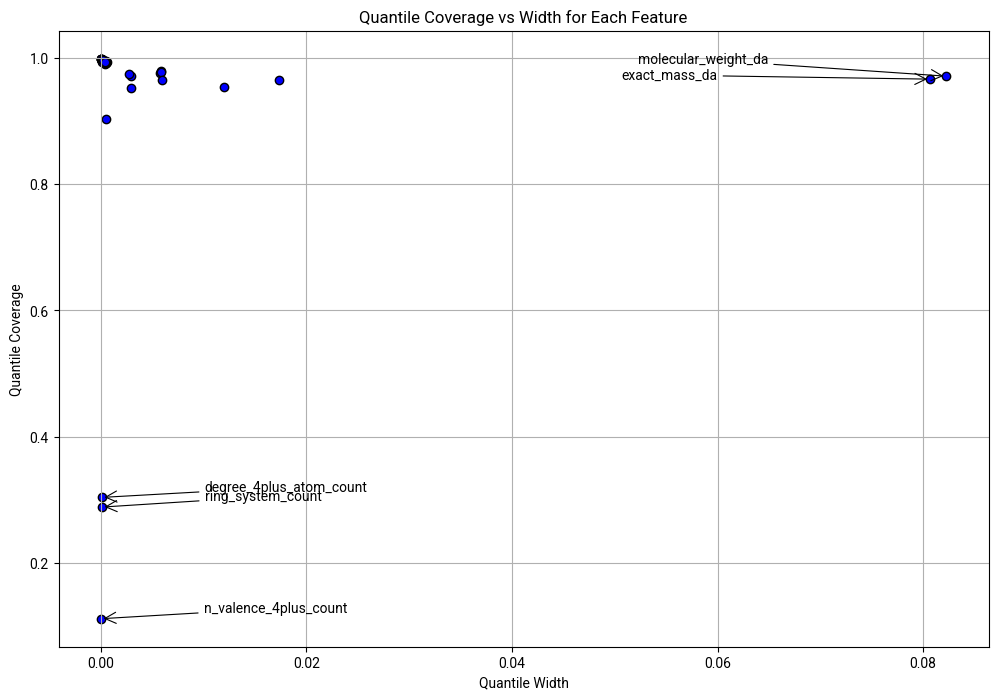

In [27]:
# Plot quantile coverage vs width for each feature as a scatter plot
efficiency = norm_width.mean(dim=0)
plt.figure(figsize=(12, 8))
plt.scatter(efficiency.cpu().numpy(), coverage_per_feature_q.cpu().numpy(), color='blue', edgecolor='black')
count = 0
for i in range(width.shape[1]):
    if (coverage_per_feature_q[i].item() < 0.4):
        plt.annotate(cont_feature_names[i], xy=(efficiency[i].item(), coverage_per_feature_q[i].item()),
                    xytext=(efficiency[i].item() + 0.01, coverage_per_feature_q[i].item() + 0.01),
                    arrowprops=dict(arrowstyle='->', lw=0.8, mutation_scale=20), fontsize=10)
    if (efficiency[i].item() > 0.05):
        plt.annotate(cont_feature_names[i], xy=(efficiency[i].item(), coverage_per_feature_q[i].item()),
                    xytext=(efficiency[i].item() - 0.03, coverage_per_feature_q[i].item() + 0.02 * count),
                    arrowprops=dict(arrowstyle='->', lw=0.8, mutation_scale=20), fontsize=10)
        count += 1
plt.xlabel("Quantile Width")
plt.ylabel("Quantile Coverage")
plt.title("Quantile Coverage vs Width for Each Feature")
plt.grid()

In [28]:
# Print each continous output along with the corresponding target value for the first sample
for i, feat in enumerate(quantiles_rounded[0]):
    print(f'Target {i}: {targets["regression"][0, i].item():.4f} ({dataset.continuous_feature_order[i]})')
    print('Predicted quantiles:')
    for q in range(feat.shape[0]):
        print(f'  Quantile {q}: {feat[q].item():.4f}')

Target 0: 0.0000 (alcohol)
Predicted quantiles:
  Quantile 0: 0.0000
  Quantile 1: 0.0000
  Quantile 2: 0.0000
Target 1: 0.0000 (aliphatic_ring_count)
Predicted quantiles:
  Quantile 0: 0.0000
  Quantile 1: 0.0000
  Quantile 2: 0.0000
Target 2: 4.0000 (branch_point_count)
Predicted quantiles:
  Quantile 0: 4.0000
  Quantile 1: 4.0000
  Quantile 2: 4.0000
Target 3: 1.0000 (chiral_center_count)
Predicted quantiles:
  Quantile 0: 1.0000
  Quantile 1: 1.0000
  Quantile 2: 1.0000
Target 4: 6.0000 (degree_1_atom_count)
Predicted quantiles:
  Quantile 0: 6.0000
  Quantile 1: 6.0000
  Quantile 2: 6.0000
Target 5: 71.0000 (degree_2_atom_count)
Predicted quantiles:
  Quantile 0: 65.0000
  Quantile 1: 70.0000
  Quantile 2: 73.0000
Target 6: 4.0000 (degree_3_atom_count)
Predicted quantiles:
  Quantile 0: 4.0000
  Quantile 1: 4.0000
  Quantile 2: 4.0000
Target 7: -0.0000 (degree_4plus_atom_count)
Predicted quantiles:
  Quantile 0: 0.0000
  Quantile 1: 0.0000
  Quantile 2: 0.0000
Target 8: 19.0000 (

In [45]:
quantiles_rounded[..., 1]

tensor([[  1.,   0.,   9.,  ...,   6., 246.,   5.],
        [ 11.,   3.,  18.,  ...,   1., 274.,  17.],
        [ -0.,   0.,   4.,  ...,   3., 126.,   1.],
        ...,
        [  5.,   1.,   8.,  ...,   1., 210.,   7.],
        [  5.,   1.,   8.,  ...,   1., 194.,   7.],
        [  4.,   1.,   7.,  ...,   1., 152.,   6.]], device='cuda:0')

In [81]:
# Compute the rounded median accuracy
median_preds = quantiles_rounded[..., 1]
median_acc = (median_preds == target).float().mean(dim=0)
for i, acc in enumerate(median_acc):
    print(f'Median accuracy for {feature_names[i]}: {acc:.4f}')

Median accuracy for alcohol: 0.9434
Median accuracy for aliphatic_ring_count: 0.9584
Median accuracy for branch_point_count: 0.8097
Median accuracy for chiral_center_count: 0.9281
Median accuracy for degree_1_atom_count: 0.9054
Median accuracy for degree_2_atom_count: 0.1719
Median accuracy for degree_3_atom_count: 0.9028
Median accuracy for degree_4plus_atom_count: 0.2844
Median accuracy for degree_of_unsaturation: 0.1797
Median accuracy for double_bond_count: 0.2231
Median accuracy for element_C: 0.1805
Median accuracy for element_H: 0.0577
Median accuracy for element_N: 0.9691
Median accuracy for element_O: 0.9059
Median accuracy for element_P: 0.9953
Median accuracy for ester: 0.9673
Median accuracy for ether: 0.9440
Median accuracy for exact_mass_da: 0.0000
Median accuracy for heavy_atom_count: 0.1760
Median accuracy for heteroatom_count: 0.9046
Median accuracy for heteroatom_exocyclic_count: 0.9018
Median accuracy for heteroatom_in_ring_count: 0.9567
Median accuracy for molecular

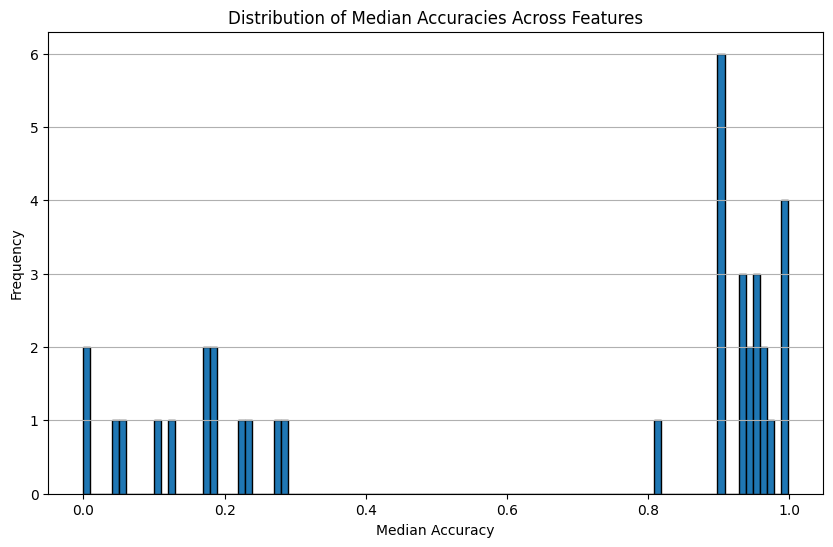

In [82]:
# Plot the distribution of median accuracies across features
plt.figure(figsize=(10, 6))
plt.hist(median_acc.cpu().numpy(), bins=100, edgecolor='black')
plt.xlabel("Median Accuracy")
plt.ylabel("Frequency")
plt.title("Distribution of Median Accuracies Across Features")
plt.grid(axis='y')
plt.show()

In [60]:
# Accuracy of binary predictions
binary_outputs = outputs['binary'].cpu()
binary_targets = targets['binary'].cpu()
binary_preds = (binary_outputs > 0.5).float()
binary_acc = (binary_preds == binary_targets).float()
binary_accs = []
for i in range(binary_outputs.shape[1]):
    acc_i = (binary_preds[:, i] == binary_targets[:, i]).float().mean().item()
    binary_accs.append(acc_i)
    print(f'Binary feature {i} accuracy: {acc_i:.4f}')

Binary feature 0 accuracy: 1.0000
Binary feature 1 accuracy: 1.0000
Binary feature 2 accuracy: 1.0000
Binary feature 3 accuracy: 0.9999
Binary feature 4 accuracy: 1.0000
Binary feature 5 accuracy: 1.0000
Binary feature 6 accuracy: 1.0000
Binary feature 7 accuracy: 1.0000
Binary feature 8 accuracy: 0.9996
Binary feature 9 accuracy: 1.0000
Binary feature 10 accuracy: 1.0000
Binary feature 11 accuracy: 0.9993
Binary feature 12 accuracy: 1.0000
Binary feature 13 accuracy: 0.9992
Binary feature 14 accuracy: 0.9998
Binary feature 15 accuracy: 0.9999
Binary feature 16 accuracy: 0.9982
Binary feature 17 accuracy: 0.9996
Binary feature 18 accuracy: 1.0000
Binary feature 19 accuracy: 0.9959
Binary feature 20 accuracy: 0.9990
Binary feature 21 accuracy: 0.9998
Binary feature 22 accuracy: 0.9974
Binary feature 23 accuracy: 0.9991
Binary feature 24 accuracy: 0.9980
Binary feature 25 accuracy: 0.9978
Binary feature 26 accuracy: 0.9951
Binary feature 27 accuracy: 0.9998
Binary feature 28 accuracy: 0.

<BarContainer object of 167 artists>

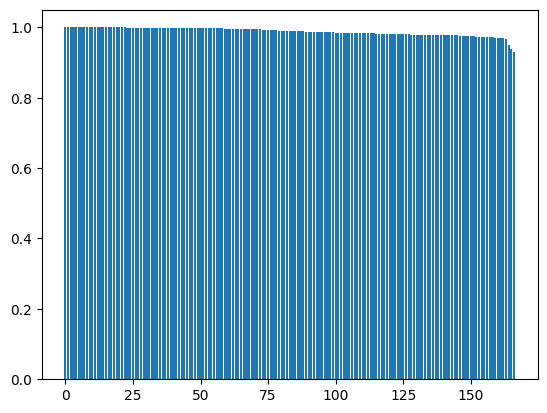

In [48]:
# Compute per feature binary accuracies
per_feature_acc = (binary_preds == binary_targets).float().mean(dim=0)
feature_accs = [per_feature_acc[i].item() for i in range(per_feature_acc.shape[0])]
sorted_indices = sorted(range(len(feature_accs)), key=lambda i: feature_accs[i], reverse=True)
plt.bar(range(len(feature_accs)), [feature_accs[i] for i in sorted_indices])

In [49]:
# index of the feature with the lowest accuracy
worst_feature_idx = feature_accs.index(min(feature_accs))
print(f'Worst performing binary feature index: {worst_feature_idx} with accuracy {feature_accs[worst_feature_idx]:.2%}')

Worst performing binary feature index: 99 with accuracy 92.94%


# Conformal

## Calibration

In [51]:
from model.conformal import calibrate_model

calibration_loader = DataLoader(calibration_ds, batch_size=256, shuffle=False)
#q_hats = calibrate_model(model, calibration_loader, alpha=0.0001953125, quantiles=[0.05, 0.5, 0.95])
q_hats = calibrate_model(model, calibration_loader, alpha=0.05, quantiles=[0.05, 0.5, 0.95])
print(f'Calibrated quantile thresholds (q_hat): {q_hats}')

KeyboardInterrupt: 

In [52]:
#torch.save(q_hats, "../models/final/multitask_mlp_mixed_q_hats.pt")
# load qhats
q_hats_loaded = torch.load("../models/final/multitask_mlp_mixed_q_hats.pt")
print(f'Loaded q_hats: {q_hats_loaded}')

Loaded q_hats: {'binary_thresholds': tensor([1.9107e-09, 2.1158e-09, 2.0198e-09, 4.7522e-05, 2.2086e-09, 2.1952e-09,
        2.1309e-09, 8.5631e-10, 5.8094e-04, 1.3450e-06, 9.1077e-10, 3.5505e-03,
        1.6168e-07, 8.5196e-04, 1.1993e-04, 1.7695e-04, 5.3555e-03, 2.5622e-03,
        2.6183e-06, 2.7393e-02, 1.3445e-03, 6.4561e-04, 1.2328e-02, 1.8328e-03,
        6.0128e-03, 2.9321e-03, 1.1916e-02, 6.0980e-04, 7.8042e-03, 1.3830e-02,
        8.5793e-03, 8.6409e-05, 5.0105e-04, 7.6833e-04, 3.0590e-02, 1.1132e-04,
        3.1060e-03, 6.4729e-03, 6.4736e-03, 5.4587e-03, 5.7864e-03, 2.7712e-03,
        1.0870e-02, 1.4976e-02, 1.0250e-03, 2.1691e-03, 5.2651e-03, 2.3370e-03,
        2.0400e-02, 2.0813e-02, 7.8611e-02, 7.3759e-03, 6.6109e-03, 2.3617e-01,
        2.0806e-01, 1.1062e-02, 7.9685e-04, 2.3167e-01, 1.1318e-02, 3.4630e-03,
        1.1776e-02, 1.1948e-02, 6.6189e-02, 1.1785e-03, 4.8683e-03, 2.3599e-02,
        1.1431e-01, 1.5638e-02, 6.8717e-05, 3.9245e-02, 2.3665e-03, 7.3434e-03,
   

In [126]:
q_hats['quantile_thresholds']

tensor([ 1.9388e-03,  1.5378e-03,  7.8261e-05,  3.0550e-03,  1.3437e-03,
        -4.9470e-02,  4.7323e-04,  1.6740e-03,  5.0331e-02,  3.3749e-02,
        -6.6912e-02,  4.2132e-03,  3.4844e-03,  6.4172e-03,  2.3967e-03,
         1.9222e-02,  2.6096e-02, -4.0676e-02, -5.4221e-02,  2.1164e-03,
         6.0831e-03,  1.8142e-03, -4.8713e-02, -2.2098e-04,  6.8384e-04,
         5.1478e-03,  2.0072e-02,  2.9340e-03,  1.4274e-03,  6.3830e-03,
         1.4393e-03, -7.5493e-03,  1.5604e-02,  7.9373e-03, -2.2322e-02,
         6.0683e-04])

In [127]:
len(outputs['categorical'])

53

In [53]:
q_hats = q_hats_loaded

## Prediction

In [54]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

In [55]:
# generate prediction sets
from model.conformal import predict_sets

test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=4, pin_memory=True)

all_prediction_sets = []
all_targets = []

for spectra, targets in tqdm(test_loader, desc="Generating prediction sets on test set"):
    targets = {
        "binary":      targets["binary"].to(device),
        "categorical": [t.to(device) for t in targets["categorical"]],
        "regression":      targets["continuous"].to(device),
    }

    prediction_sets = predict_sets(model, spectra, q_hats)
    all_prediction_sets.append(prediction_sets)
    all_targets.append(targets)

Generating prediction sets on test set:   0%|          | 0/237 [00:00<?, ?it/s]

Generating prediction sets on test set: 100%|██████████| 237/237 [00:47<00:00,  5.04it/s]


In [34]:
prediction_sets['categorical'][3].shape

torch.Size([40, 2])

In [56]:
# Consolidate prediction sets
num_cat_features = prediction_sets['categorical'][0].shape[0]
all_prediction_sets = {
    "binary": torch.cat([ps["binary"] for ps in all_prediction_sets], dim=0),
    "categorical": [torch.cat([ps["categorical"][i] for ps in all_prediction_sets], dim=0) for i in range(num_cat_features)],
    "quantile": torch.cat([ps["quantile"] for ps in all_prediction_sets], dim=0),
}
all_targets = {
    "binary": torch.cat([t["binary"] for t in all_targets], dim=0),
    "categorical": [torch.cat([t["categorical"][i] for t in all_targets], dim=0) for i in range(num_cat_features)],
    "regression": torch.cat([t["regression"] for t in all_targets], dim=0),
}

In [57]:
prediction_sets = all_prediction_sets
targets = all_targets

In [58]:
# Calculate coverage of the prediction sets for the binary features
# [True, False] -> {0}
# [False, True] -> {1}
# [True, True] -> {0, 1}

binary_ps = prediction_sets['binary'].to(device)          # (N, F, 2), bool
binary_t  = targets['binary'].long().to(device)           # (N, F)

binary_covered  = binary_ps.gather(-1, binary_t.unsqueeze(-1)).squeeze(-1)   # (N, F) bool
binary_coverage = binary_covered.float().mean(dim=0)                  # (F,)

for f, c in enumerate(binary_coverage.tolist()):
    print(f'Binary feature {f} coverage: {c:.2%}')

Binary feature 0 coverage: 100.00%
Binary feature 1 coverage: 100.00%
Binary feature 2 coverage: 100.00%
Binary feature 3 coverage: 100.00%
Binary feature 4 coverage: 100.00%
Binary feature 5 coverage: 100.00%
Binary feature 6 coverage: 100.00%
Binary feature 7 coverage: 100.00%
Binary feature 8 coverage: 99.97%
Binary feature 9 coverage: 100.00%
Binary feature 10 coverage: 100.00%
Binary feature 11 coverage: 99.95%
Binary feature 12 coverage: 100.00%
Binary feature 13 coverage: 99.95%
Binary feature 14 coverage: 99.98%
Binary feature 15 coverage: 99.99%
Binary feature 16 coverage: 99.83%
Binary feature 17 coverage: 99.93%
Binary feature 18 coverage: 99.99%
Binary feature 19 coverage: 99.59%
Binary feature 20 coverage: 99.85%
Binary feature 21 coverage: 99.98%
Binary feature 22 coverage: 99.77%
Binary feature 23 coverage: 99.91%
Binary feature 24 coverage: 99.78%
Binary feature 25 coverage: 99.82%
Binary feature 26 coverage: 99.46%
Binary feature 27 coverage: 99.98%
Binary feature 28 c

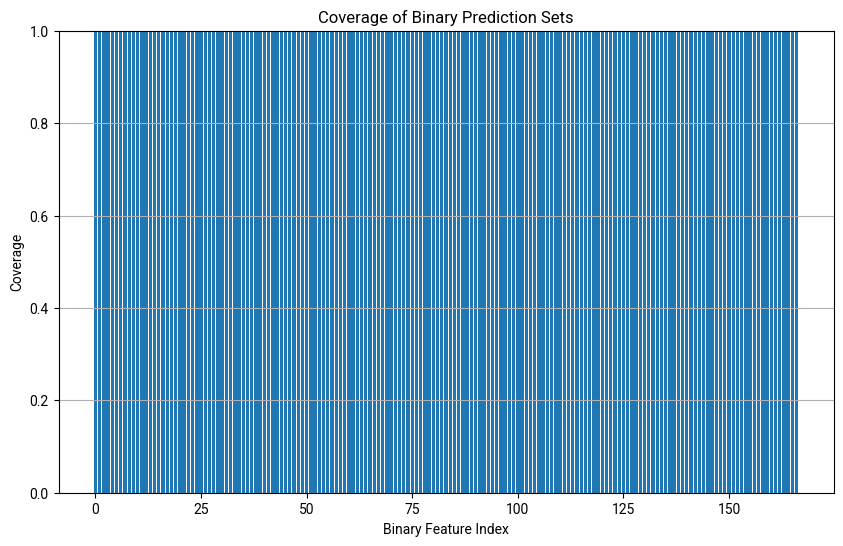

In [38]:
# Visualise the coverage of the binary prediction sets without feature names
plt.figure(figsize=(10, 6))
plt.bar(range(len(binary_coverage)), binary_coverage.cpu().numpy())
plt.xlabel("Binary Feature Index")
plt.ylabel("Coverage")
plt.title("Coverage of Binary Prediction Sets")
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

AttributeError: 'NoneType' object has no attribute 'get'

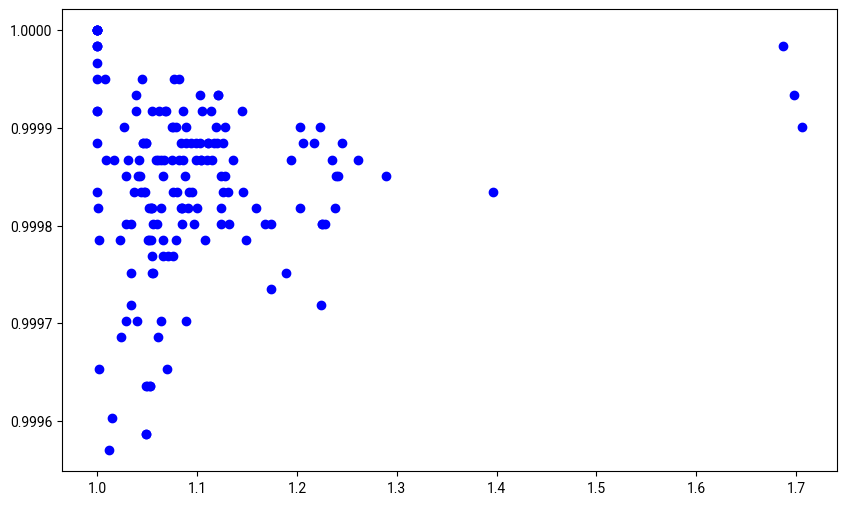

In [39]:
# Scatter plot of coverage vs efficiency (set size) for binary features
binary_set_sizes = binary_ps.sum(dim=-1).float()  # (N, F), values in {1, 2}
binary_efficiency = binary_set_sizes.mean(dim=0)   # (F,), average set
plt.figure(figsize=(10, 6))
plt.scatter(binary_efficiency.cpu().numpy(), binary_coverage.cpu().numpy(), color='blue')
worst_efficiency_indices = np.where(binary_efficiency.cpu().numpy() > 1.001)[0]
for idx in worst_efficiency_indices:
    plt.annotate(f'{MACCS_DEFINITIONS.get(idx).get('predicate')}', (binary_efficiency[idx].item(), binary_coverage[idx].item()), textcoords="offset points", xytext=(0,10), ha='center')
plt.xlabel("Average Binary Prediction Set Size")
plt.ylabel("Coverage")
plt.title("Coverage vs Efficiency for Binary Features")
plt.grid()
plt.show()

In [52]:
# indices of the three features with the worst efficiency
worst_efficiency_indices = torch.argsort(binary_efficiency)[:3]
print(f'Indices of the three binary features with the worst efficiency: {worst_efficiency_indices.tolist()}')

Indices of the three binary features with the worst efficiency: [0, 1, 2]


In [58]:
np.where(binary_efficiency.cpu().numpy() > 1.001)

(array([ 99, 115, 116]),)

In [20]:
# Find features with the worst coverage
worst_coverage_idx = torch.argmin(coverage).item()
print(f'Worst coverage binary feature index: {worst_coverage_idx} with coverage {coverage[worst_coverage_idx]:.2%}')

Worst coverage binary feature index: 99 with coverage 95.02%


In [25]:
# Print raw predictions (logits) for the worst coverage feature
worst_logits = outputs['binary'][:, worst_coverage_idx]  # (N, 2)
worst_targets = targets['binary'][:, worst_coverage_idx]  # (N,)
for i in range(10):
    print(f'Sample {i}: Target={worst_targets[i].item()}, Logits={worst_logits[i].tolist()}, Sigmoid={torch.sigmoid(worst_logits[i]).tolist()}')

Sample 0: Target=1.0, Logits=2.9759907722473145, Sigmoid=0.951477587223053
Sample 1: Target=1.0, Logits=5.738689422607422, Sigmoid=0.9967913031578064
Sample 2: Target=1.0, Logits=4.80720853805542, Sigmoid=0.9918956160545349
Sample 3: Target=1.0, Logits=4.1165313720703125, Sigmoid=0.9839605689048767
Sample 4: Target=1.0, Logits=-1.3525173664093018, Sigmoid=0.2054591178894043
Sample 5: Target=1.0, Logits=0.26538825035095215, Sigmoid=0.5659603476524353
Sample 6: Target=1.0, Logits=4.273745536804199, Sigmoid=0.9862619042396545
Sample 7: Target=1.0, Logits=5.186470031738281, Sigmoid=0.9944393634796143
Sample 8: Target=1.0, Logits=5.017256736755371, Sigmoid=0.9934208989143372
Sample 9: Target=1.0, Logits=3.55039381980896, Sigmoid=0.972088098526001


In [26]:
# Print average prediction set size for binary features
set_sizes = prediction_sets['binary'].sum(dim=-1)  # (N, F)
avg_set_size = set_sizes.float().mean(dim=0)      # (F,)
for f, s in enumerate(avg_set_size.tolist()):
    print(f'Binary feature {f} average prediction set size: {s:.8f}')

Binary feature 0 average prediction set size: 1.00000000
Binary feature 1 average prediction set size: 1.00000000
Binary feature 2 average prediction set size: 1.00000000
Binary feature 3 average prediction set size: 1.00000000
Binary feature 4 average prediction set size: 1.00000000
Binary feature 5 average prediction set size: 1.00000000
Binary feature 6 average prediction set size: 1.00000000
Binary feature 7 average prediction set size: 1.00000000
Binary feature 8 average prediction set size: 1.00000000
Binary feature 9 average prediction set size: 1.00000000
Binary feature 10 average prediction set size: 1.00000000
Binary feature 11 average prediction set size: 1.00000000
Binary feature 12 average prediction set size: 1.00000000
Binary feature 13 average prediction set size: 1.00000000
Binary feature 14 average prediction set size: 1.00000000
Binary feature 15 average prediction set size: 1.00000000
Binary feature 16 average prediction set size: 1.00000000
Binary feature 17 averag

In [59]:
# Calculate coverage for the categorical features
cat_ps = [ps.to(device) for ps in prediction_sets['categorical']]  # List of (N, K_i) bool
cat_t = [t.long().to(device) for t in targets['categorical']]        # List of (N,) long

cat_ps = torch.stack(cat_ps, dim=1)  # (N, F, K_max) bool
cat_t = torch.stack(cat_t, dim=1)    # (N, F) long

cat_covered = cat_ps.gather(-1, cat_t.unsqueeze(-1)).squeeze(-1)
cat_coverage = cat_covered.float().mean(dim=0)
for i, c in enumerate(cat_coverage.tolist()):
    print(f'Categorical feature {i} coverage: {c:.2%}')

Categorical feature 0 coverage: 99.87%
Categorical feature 1 coverage: 98.84%
Categorical feature 2 coverage: 98.95%
Categorical feature 3 coverage: 99.65%
Categorical feature 4 coverage: 98.77%
Categorical feature 5 coverage: 98.41%
Categorical feature 6 coverage: 98.97%
Categorical feature 7 coverage: 99.34%
Categorical feature 8 coverage: 100.00%
Categorical feature 9 coverage: 98.70%
Categorical feature 10 coverage: 98.77%
Categorical feature 11 coverage: 99.91%
Categorical feature 12 coverage: 98.68%
Categorical feature 13 coverage: 99.61%
Categorical feature 14 coverage: 98.52%
Categorical feature 15 coverage: 99.84%
Categorical feature 16 coverage: 99.99%
Categorical feature 17 coverage: 99.92%
Categorical feature 18 coverage: 99.50%
Categorical feature 19 coverage: 99.78%
Categorical feature 20 coverage: 99.98%
Categorical feature 21 coverage: 99.34%
Categorical feature 22 coverage: 99.85%
Categorical feature 23 coverage: 99.90%
Categorical feature 24 coverage: 98.08%
Categoric

Worst efficiency categorical feature index: 0 with efficiency 1.0000


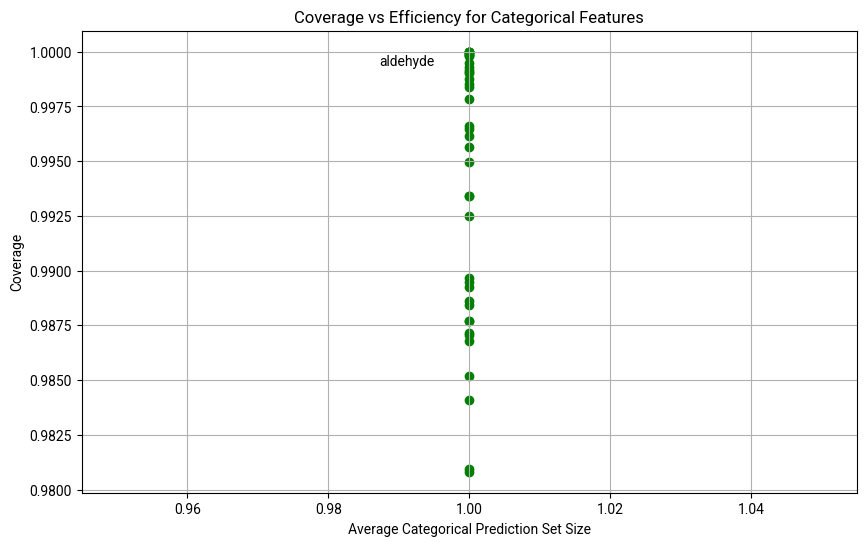

In [60]:
# Scatter plot of coverage vs efficiency (set size) for the categorical features
cat_set_sizes = cat_ps.sum(dim=-1).float()  # (N, F), values in {1, 2, ..., K_i}
cat_efficiency = cat_set_sizes.mean(dim=0)   # (F,), average set
plt.figure(figsize=(10, 6))
plt.scatter(cat_efficiency.cpu().numpy(), cat_coverage.cpu().numpy(), color='green')
# Annotate point with the worst efficiency
worst_cat_efficiency_idx = torch.argmax(cat_efficiency).item()
print(f'Worst efficiency categorical feature index: {worst_cat_efficiency_idx} with efficiency {cat_efficiency[worst_cat_efficiency_idx]:.4f}')
plt.annotate(f'{model.categorical_names[worst_cat_efficiency_idx]}', (cat_efficiency[worst_cat_efficiency_idx].item(), cat_coverage[worst_cat_efficiency_idx].item()), textcoords="offset points", xytext=(-45,10), ha='center')
plt.xlabel("Average Categorical Prediction Set Size")
plt.ylabel("Coverage")
plt.title("Coverage vs Efficiency for Categorical Features")
plt.grid()
plt.show()

In [29]:
prediction_sets.keys()

dict_keys(['binary', 'categorical', 'quantile'])

In [61]:
ps = prediction_sets['quantile'].to(device)  # (N, F, 2)
t = targets['regression'].to(device)        # (N, F)

lower = ps[..., 0]
upper = ps[..., 1]

q_within = (t >= lower) & (t <= upper)
q_coverage = q_within.float().mean(dim=0)
for i, c in enumerate(q_coverage.tolist()):
    print(f'Quantile regression feature {i} coverage: {c:.2%}')

Quantile regression feature 0 coverage: 95.13%
Quantile regression feature 1 coverage: 94.82%
Quantile regression feature 2 coverage: 95.04%
Quantile regression feature 3 coverage: 95.03%
Quantile regression feature 4 coverage: 95.33%
Quantile regression feature 5 coverage: 94.99%
Quantile regression feature 6 coverage: 95.06%
Quantile regression feature 7 coverage: 95.00%
Quantile regression feature 8 coverage: 95.07%
Quantile regression feature 9 coverage: 95.08%
Quantile regression feature 10 coverage: 94.85%
Quantile regression feature 11 coverage: 94.95%
Quantile regression feature 12 coverage: 94.91%
Quantile regression feature 13 coverage: 94.90%
Quantile regression feature 14 coverage: 94.89%
Quantile regression feature 15 coverage: 95.16%
Quantile regression feature 16 coverage: 94.91%
Quantile regression feature 17 coverage: 94.80%
Quantile regression feature 18 coverage: 94.80%
Quantile regression feature 19 coverage: 94.98%
Quantile regression feature 20 coverage: 94.83%
Qu

In [139]:
len(width.mean(dim=0)), len(coverage)

(36, 36)

In [66]:
cont_feature_names = dataset.continuous_feature_order
cont_feature_names

['alcohol',
 'aliphatic_ring_count',
 'branch_point_count',
 'chiral_center_count',
 'degree_1_atom_count',
 'degree_2_atom_count',
 'degree_3_atom_count',
 'degree_4plus_atom_count',
 'degree_of_unsaturation',
 'double_bond_count',
 'element_C',
 'element_H',
 'element_N',
 'element_O',
 'element_P',
 'ester',
 'ether',
 'exact_mass_da',
 'heavy_atom_count',
 'heteroatom_count',
 'heteroatom_exocyclic_count',
 'heteroatom_in_ring_count',
 'molecular_weight_da',
 'n_valence_4plus_count',
 'o_valence_1_count',
 'o_valence_2_count',
 'p_valence_5plus_count',
 'phosphate',
 'ring_count',
 'ring_size_6_count',
 'ring_system_count',
 'rotatable_bond_count',
 'stereo_double_bond_Z_count',
 'stereo_double_bond_unspecified_count',
 'total_atom_count_with_h',
 'unassigned_chiral_center_count']

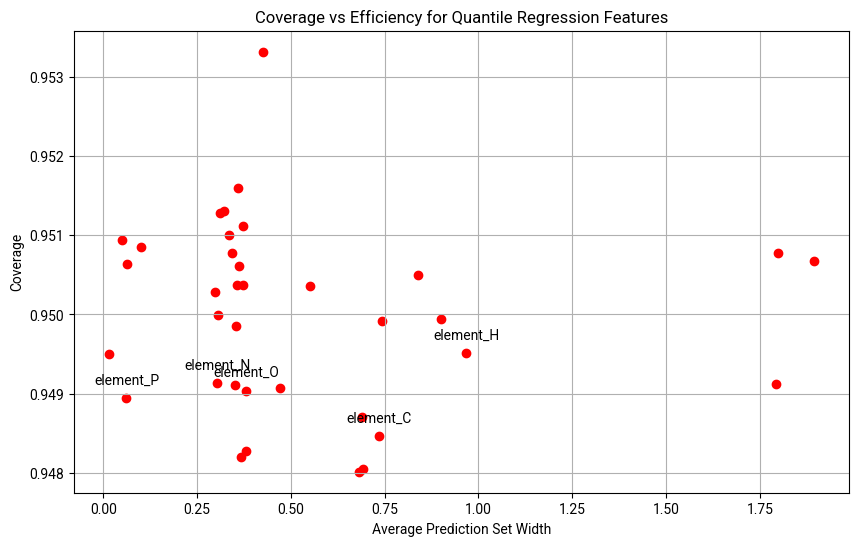

In [67]:
# Scatter plot of coverage vs efficiency (set size) for the quantile regression features
width = upper - lower
plt.figure(figsize=(10, 6))
plt.scatter(width.mean(dim=0).cpu().numpy(), q_coverage.cpu().numpy(), color='red')
# Annotate the points with width above 1.75
for i, (w, c) in enumerate(zip(width.mean(dim=0).cpu().numpy(), q_coverage.cpu().numpy())):
    if 'element' in cont_feature_names[i]:
        plt.annotate(f'{cont_feature_names[i]}', (w, c), textcoords="offset points", xytext=(0,10), ha='center')

plt.xlabel("Average Prediction Set Width")
plt.ylabel("Coverage")
plt.title("Coverage vs Efficiency for Quantile Regression Features")
plt.grid()
plt.show()

In [47]:
atom_count_indices = [dataset.continuous_feature_order.index(f) for f in dataset.continuous_feature_order if 'count' in f]
for idx in atom_count_indices:
    print(f'Feature {cont_feature_names[idx]}')

Feature aliphatic_ring_count
Feature branch_point_count
Feature chiral_center_count
Feature degree_1_atom_count
Feature degree_2_atom_count
Feature degree_3_atom_count
Feature degree_4plus_atom_count
Feature double_bond_count
Feature heavy_atom_count
Feature heteroatom_count
Feature heteroatom_exocyclic_count
Feature heteroatom_in_ring_count
Feature n_valence_4plus_count
Feature o_valence_1_count
Feature o_valence_2_count
Feature p_valence_5plus_count
Feature ring_count
Feature ring_size_6_count
Feature ring_system_count
Feature rotatable_bond_count
Feature stereo_double_bond_Z_count
Feature stereo_double_bond_unspecified_count
Feature total_atom_count_with_h
Feature unassigned_chiral_center_count


In [143]:
lower.shape

torch.Size([60456, 36])

In [48]:
# Calculate widths after undoing the normalisation, rounding, and then renormalising to get a fair comparison of efficiency
mean = torch.tensor(mean).to(device)
std = torch.tensor(std).to(device)
lower_unnorm = lower * std[None, :] + mean[None, :]
upper_unnorm = upper * std[None, :] + mean[None, :]
lower_rounded = torch.round(lower_unnorm)
upper_rounded = torch.round(upper_unnorm)
lower_renorm = (lower_rounded - mean[None, :]) / std[None, :]
upper_renorm = (upper_rounded - mean[None, :]) / std[None, :]
width_renorm = upper_renorm - lower_renorm
plt.figure(figsize=(10, 6))
plt.scatter(width_renorm.mean(dim=0).cpu().numpy(), coverage.cpu().numpy(), color='purple')
plt.xlabel("Average Prediction Set Width (Rounded)")
plt.ylabel("Coverage")
plt.title("Coverage vs Efficiency for Quantile Regression Features (Rounded)")
plt.grid()
plt.show()

NameError: name 'coverage' is not defined

<Figure size 1000x600 with 0 Axes>

In [49]:
# How many samples have every single feature (binary, categorical, and quantile) covered by the prediction set?
all_binary_covered = binary_covered.all(dim=-1)  # (N,), True if all binary
all_categorical_covered = cat_covered.all(dim=-1)  # (N,), True if all categorical
all_quantile_covered = q_within.all(dim=-1)  # (N,), True if all quantile
all_covered = all_binary_covered & all_categorical_covered & all_quantile_covered
overall_coverage = all_covered.float().mean().item()
print(f'Overall coverage (all features simultaneously): {overall_coverage:.2%}')

Overall coverage (all features simultaneously): 99.06%


In [41]:
binary_covered[2]

tensor([True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, Tr

In [182]:
all_binary_covered[2]

tensor(True, device='cuda:0')

In [42]:
sample = 2
# Convert the predictions of sample 2 to ASP constraints
from predicates.interface import PredictionInterface
from predicates.compiler import compile_asp_constraint

In [ ]:
# convert prediction so sample 2 to a dictionary of the form:
# {
#     key: PredictionEntry(pred_set)
# }
# key is the key found in schema
